# ARGus id90 — análisis de los genes que el modelo clasifica mal

**Para qué:** encontrar los genes del 1k+1k donde el modelo se equivoca, aislarlos en archivos FASTA y
subirlos al BLAST web de NCBI para ver *por qué* se confunde.

Corre las celdas en orden. Lo único que puede necesitar ajuste es `INTERIM_MANUAL` en la celda 1.

Al terminar, todo queda en `results/errores_id90/`.

## Celda 1 — Configuración

Carga el modelo **guardado** `argus_rf_k6_id90.joblib` (el mismo que usa la GUI) y deduce `K` del número
de columnas que espera, así que no hay que configurarlo a mano. El umbral y el tamaño de ventana se leen
del propio paquete.

Si tu `.joblib` está en `models/` en lugar de `data/models/`, lo encuentra igual.

In [1]:
import os, re, json, joblib
from pathlib import Path
from itertools import product
import numpy as np, pandas as pd

INTERIM_MANUAL = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim"
INTERIM = Path(INTERIM_MANUAL)
if not (INTERIM / "muestra_genes_completos.fasta").exists():
    hits = []
    for raiz in (Path("/mnt/c/Users"), Path("C:/Users"), Path.home()):
        if raiz.exists(): hits += list(raiz.rglob("muestra_genes_completos.fasta"))
    assert hits, "No encontré muestra_genes_completos.fasta: corrige INTERIM_MANUAL"
    INTERIM = hits[0].parent
print("INTERIM =", INTERIM)

IDENTIDAD = 90
RAIZ      = INTERIM.parent.parent
MODELOS   = INTERIM.parent / "models"
SALIDA    = RAIZ / "results" / f"errores_id{IDENTIDAD}"
SALIDA.mkdir(parents=True, exist_ok=True)

FASTA_1K1K = INTERIM / "muestra_genes_completos.fasta"
LABELS_1K1K = INTERIM / "muestra_genes_labels.tsv"

# el .joblib puede estar en data/models/ o en models/ según el cuaderno que lo guardó
cand = [MODELOS / f"argus_rf_k6_id{IDENTIDAD}.joblib",
        RAIZ / "models" / f"argus_rf_k6_id{IDENTIDAD}.joblib"]
RUTA_MODELO = next((p for p in cand if p.exists()), None)
assert RUTA_MODELO, f"No encontré el modelo. Busqué en:\n  " + "\n  ".join(str(c) for c in cand)

paq = joblib.load(RUTA_MODELO)
rf = paq["modelo"] if isinstance(paq, dict) else paq
UMBRAL = float(paq.get("umbral", 0.5)) if isinstance(paq, dict) else 0.5
VENTANA = int(paq.get("ventana", 500)) if isinstance(paq, dict) else 500

K = 1                                        # K se deduce del nº de columnas del modelo
while 4 ** K < rf.n_features_in_: K += 1
assert 4 ** K == rf.n_features_in_, f"El modelo espera {rf.n_features_in_} columnas; no es 4**K"
try: rf.set_params(n_jobs=-1)
except Exception: pass

print(f"modelo: {RUTA_MODELO.name} | K={K} | ventana={VENTANA} | umbral={UMBRAL}")

INTERIM = /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim
modelo: argus_rf_k6_id90.joblib | K=6 | ventana=500 | umbral=0.5


## Celda 2 — Predecir los 2000 genes

Fragmenta cada gen a 500 pb (relleno con `0` a la derecha, igual que en el entrenamiento) y guarda **la
probabilidad de cada fragmento**, no solo la del gen. Eso es lo que permite después señalar *qué parte* de
un gen largo disparó la alarma, que es justo la hipótesis de la asesora.

Deja dos archivos: `predicciones_por_gen.csv` y `predicciones_por_fragmento.csv`.

In [2]:
LUT = np.full(256, 4, dtype=np.int8)
for i, b in enumerate(b"ACGT"): LUT[b] = i
POT = (4 ** np.arange(K - 1, -1, -1)).astype(np.int64)

def vector_kmer(seq):
    a = LUT[np.frombuffer(seq.upper().encode("ascii", "replace"), dtype=np.uint8)]
    out = np.zeros(4 ** K, dtype=np.float32)
    if len(a) - K + 1 <= 0: return out
    win = np.lib.stride_tricks.sliding_window_view(a, K)
    ok = (win < 4).all(axis=1)
    if not ok.any(): return out
    idx = (win[ok].astype(np.int64) * POT).sum(axis=1)
    out += np.bincount(idx, minlength=4 ** K).astype(np.float32)
    return out / out.sum()

def leer_fasta(path):
    d, cur, chunks = {}, None, []
    for l in open(path):
        l = l.strip()
        if l.startswith(">"):
            if cur: d[cur] = "".join(chunks)
            cur, chunks = l[1:].split()[0], []
        elif cur: chunks.append(l)
    if cur: d[cur] = "".join(chunks)
    return d

def fragmentar(seq, ventana=VENTANA):
    seq = seq.upper(); L = len(seq)
    if L < ventana: return [seq + "0" * (ventana - L)]
    n = L // ventana
    fr = [seq[i*ventana:(i+1)*ventana] for i in range(n)]
    r = L - n * ventana
    if r > 0: fr.append(seq[n*ventana:] + "0" * (ventana - r))
    return fr

fa = leer_fasta(FASTA_1K1K)
lab = pd.read_csv(LABELS_1K1K, sep="\t")
y_1k = dict(zip(lab.iloc[:, 0].astype(str).str.split().str[0], lab.iloc[:, 1].astype(int)))
ids = [g for g in fa if g in y_1k]
print(f"genes con secuencia y etiqueta: {len(ids)} de {len(y_1k)}")

filas, detalle = [], []
for n, gid in enumerate(ids, 1):
    seq = fa[gid]
    frs = fragmentar(seq)
    X = np.array([vector_kmer(f) for f in frs], dtype=np.float32)
    p = rf.predict_proba(X)[:, 1]
    pos = p >= UMBRAL
    i_max = int(p.argmax())
    filas.append(dict(gen=gid, y=y_1k[gid], largo=len(seq), n_frag=len(frs),
                      n_frag_pos=int(pos.sum()), frac_pos=float(pos.mean()),
                      p_max=float(p.max()), p_media=float(p.mean()),
                      frag_culpable=i_max, ini_culpable=i_max * VENTANA,
                      pred_or=int(pos.any())))
    for j, (f, pj) in enumerate(zip(frs, p)):
        detalle.append((gid, j, j * VENTANA, float(pj), int(pj >= UMBRAL)))
    if n % 250 == 0: print(f"  {n}/{len(ids)}")

res = pd.DataFrame(filas)
det = pd.DataFrame(detalle, columns=["gen", "frag", "inicio", "p", "pos"])
res.to_csv(SALIDA / "predicciones_por_gen.csv", index=False)
det.to_csv(SALIDA / "predicciones_por_fragmento.csv", index=False)
print("genes:", len(res), "| fragmentos:", len(det))

genes con secuencia y etiqueta: 2000 de 2000
  250/2000
  500/2000
  750/2000
  1000/2000
  1250/2000
  1500/2000
  1750/2000
  2000/2000
genes: 2000 | fragmentos: 4667


## Celda 3 — Cuántos errores hay, y de qué tipo

Aquí sale el número real de falsos positivos. **Atención con la aritmética:** "1228 detectados − 1000 = 228"
no da los falsos positivos, porque el modelo no detecta los 1000 positivos. Con recall 0.896 detecta ~896,
así que si marcó 1228 genes, unos **332 son falsos positivos** y además **~104 ARG se le escaparon**
(falsos negativos). El 228 es solo el *exceso neto* (FP − FN).

La celda imprime los cuatro números exactos de tu corrida.

In [3]:
res["tipo"] = np.select(
    [(res.y == 1) & (res.pred_or == 1), (res.y == 0) & (res.pred_or == 1),
     (res.y == 1) & (res.pred_or == 0), (res.y == 0) & (res.pred_or == 0)],
    ["VP (acierto ARG)", "FP (falso positivo)", "FN (ARG perdido)", "VN (acierto no-ARG)"],
    default="")

n = res.tipo.value_counts()
VP = n.get("VP (acierto ARG)", 0); FP = n.get("FP (falso positivo)", 0)
FN = n.get("FN (ARG perdido)", 0); VN = n.get("VN (acierto no-ARG)", 0)

print(f"""
                   Predijo no-ARG   Predijo ARG
  Real ARG (1)        {FN:>8}       {VP:>8}
  Real no-ARG (0)     {VN:>8}       {FP:>8}

Detectados como ARG en total : {VP + FP}
  de ellos correctos (VP)    : {VP}
  de ellos equivocados (FP)  : {FP}   <-- estos son los falsos positivos
ARG reales que se perdieron  : {FN}   <-- falsos negativos (el modelo los "deja escapar")

recall    = VP/(VP+FN) = {VP/(VP+FN):.3f}
precision = VP/(VP+FP) = {VP/(VP+FP):.3f}
F1                     = {2*VP/(2*VP+FP+FN):.3f}
""")
NPOS = int((res.y == 1).sum())
print(f"OJO: 'detectados - nº de positivos reales' NO es el número de falsos positivos.")
print(f"     {VP+FP} detectados - {NPOS} positivos reales = {VP+FP-NPOS}, pero los FP son {FP}")
print(f"     y además hay {FN} ARG perdidos. La resta solo da el EXCESO NETO (FP - FN).")


                   Predijo no-ARG   Predijo ARG
  Real ARG (1)             104            896
  Real no-ARG (0)          668            332

Detectados como ARG en total : 1228
  de ellos correctos (VP)    : 896
  de ellos equivocados (FP)  : 332   <-- estos son los falsos positivos
ARG reales que se perdieron  : 104   <-- falsos negativos (el modelo los "deja escapar")

recall    = VP/(VP+FN) = 0.896
precision = VP/(VP+FP) = 0.730
F1                     = 0.804

OJO: 'detectados - nº de positivos reales' NO es el número de falsos positivos.
     1228 detectados - 1000 positivos reales = 228, pero los FP son 332
     y además hay 104 ARG perdidos. La resta solo da el EXCESO NETO (FP - FN).


## Celda 4 — Aislar los errores

Escribe tres FASTA:

| Archivo | Qué contiene | Para qué |
|---|---|---|
| `falsos_positivos_genes.fasta` | el gen completo de cada FP | lo que pidió la asesora |
| `falsos_positivos_fragmentos.fasta` | **solo el fragmento de 500 pb que disparó la alarma** | prueba directa de su hipótesis |
| `falsos_negativos_genes.fasta` | los ARG que se escaparon | el otro error, que también conviene ver |

El segundo archivo es el importante. Si la sospecha es que *una parte* de un gen largo se parece a un ARG,
hacerle BLAST al gen completo diluye la señal: el parecido local queda enterrado entre miles de bases que no
se parecen a nada. El fragmento culpable va sin el relleno de ceros, porque BLAST no acepta esos caracteres.

In [4]:
def escribir_fasta(ruta, registros):
    with open(ruta, "w") as f:
        for cab, s in registros:
            f.write(f">{cab}\n")
            for i in range(0, len(s), 70): f.write(s[i:i+70] + "\n")
    print(f"  {ruta.name}: {len(registros)} secuencias")

fp = res[res.tipo.str.startswith("FP")].sort_values("p_max", ascending=False)
fn = res[res.tipo.str.startswith("FN")].sort_values("p_max")

print("Archivos para BLAST:")
# a) genes completos mal clasificados
escribir_fasta(SALIDA / "falsos_positivos_genes.fasta",
               [(f"{r.gen} FP largo={r.largo} pmax={r.p_max:.2f} fragpos={r.n_frag_pos}/{r.n_frag}",
                 fa[r.gen]) for r in fp.itertuples()])
escribir_fasta(SALIDA / "falsos_negativos_genes.fasta",
               [(f"{r.gen} FN largo={r.largo} pmax={r.p_max:.2f}", fa[r.gen]) for r in fn.itertuples()])

# b) SOLO el fragmento que disparó la alarma (prueba directa de la hipótesis de la asesora)
frag_culpables = []
for r in fp.itertuples():
    frs = fragmentar(fa[r.gen])
    s = frs[r.frag_culpable].rstrip("0")          # sin el relleno de ceros
    frag_culpables.append((f"{r.gen}__frag{r.frag_culpable} pos={r.ini_culpable}-{r.ini_culpable+len(s)} p={r.p_max:.2f}", s))
escribir_fasta(SALIDA / "falsos_positivos_fragmentos.fasta", frag_culpables)

cols = ["gen", "tipo", "y", "largo", "n_frag", "n_frag_pos", "frac_pos", "p_max",
        "p_media", "frag_culpable", "ini_culpable"]
res[res.tipo.str.startswith(("FP", "FN"))][cols].to_csv(SALIDA / "errores_detalle.csv", index=False)
print(f"  errores_detalle.csv: {FP+FN} filas")
print("\nLos 10 falsos positivos con mayor probabilidad:")
print(fp.head(10)[["gen", "largo", "n_frag", "n_frag_pos", "p_max"]].to_string(index=False))

Archivos para BLAST:
  falsos_positivos_genes.fasta: 332 secuencias
  falsos_negativos_genes.fasta: 104 secuencias
  falsos_positivos_fragmentos.fasta: 332 secuencias
  errores_detalle.csv: 436 filas

Los 10 falsos positivos con mayor probabilidad:
                             gen  largo  n_frag  n_frag_pos    p_max
GCF_000009045.1|NC_000964.3_4136   1761       4           4 0.905000
GCF_000008865.2|NC_002695.2_3923   1188       3           3 0.845000
GCF_000025985.1|NC_003228.3_1078   1017       3           1 0.829641
GCF_000412675.1|NC_021505.1_2575    510       2           1 0.801038
 GCF_000025985.1|NC_003228.3_703   1164       3           3 0.790000
 GCF_000025985.1|NC_003228.3_970    876       2           2 0.785000
GCF_000025985.1|NC_003228.3_1290   1305       3           3 0.765000
GCF_000005845.2|NC_000913.3_3419   1239       3           2 0.740000
 GCF_000008865.2|NC_002695.2_284    459       1           1 0.735000
GCF_000009045.1|NC_000964.3_3484    612       2           2 0

## Celda 5 — Lotes para el BLAST web

El BLAST web de NCBI acepta hasta 1,000,000 pb por consulta y tiene un tope de tiempo de CPU por envío, así
que un archivo con cientos de genes se puede rechazar o quedar a medias. Esta celda parte los FASTA en lotes
de 50 secuencias.

**Empieza por los lotes `fp_frag_*`** (los fragmentos culpables): son más chicos, más rápidos y responden
mejor la pregunta.

In [5]:
# Límites del BLAST web de NCBI: 1,000,000 pb por consulta y un tope de tiempo de CPU
# por envío. Con lotes de 50 secuencias no se topa con ninguno de los dos.
POR_LOTE = 50
def lotes(origen, prefijo):
    seqs, cab, chunks = [], None, []
    for l in open(origen):
        l = l.rstrip("\n")
        if l.startswith(">"):
            if cab: seqs.append((cab, "".join(chunks)))
            cab, chunks = l, []
        else: chunks.append(l)
    if cab: seqs.append((cab, "".join(chunks)))
    d = SALIDA / "blast_lotes"; d.mkdir(exist_ok=True)
    for i in range(0, len(seqs), POR_LOTE):
        p = d / f"{prefijo}_lote{i//POR_LOTE + 1:02d}.fasta"
        with open(p, "w") as f:
            for c, s in seqs[i:i+POR_LOTE]: f.write(f"{c}\n{s}\n")
        print(f"  {p.name}: {len(seqs[i:i+POR_LOTE])} secuencias, {sum(len(s) for _, s in seqs[i:i+POR_LOTE]):,} pb")

print("Lotes de fragmentos culpables (empieza por estos):")
lotes(SALIDA / "falsos_positivos_fragmentos.fasta", "fp_frag")
print("\nLotes de genes completos:")
lotes(SALIDA / "falsos_positivos_genes.fasta", "fp_gen")
print(f"\nCarpeta: {SALIDA / 'blast_lotes'}")

Lotes de fragmentos culpables (empieza por estos):
  fp_frag_lote01.fasta: 50 secuencias, 9,085 pb
  fp_frag_lote02.fasta: 50 secuencias, 16,567 pb
  fp_frag_lote03.fasta: 50 secuencias, 16,798 pb
  fp_frag_lote04.fasta: 50 secuencias, 18,417 pb
  fp_frag_lote05.fasta: 50 secuencias, 20,859 pb
  fp_frag_lote06.fasta: 50 secuencias, 17,993 pb
  fp_frag_lote07.fasta: 32 secuencias, 12,129 pb

Lotes de genes completos:
  fp_gen_lote01.fasta: 50 secuencias, 50,658 pb
  fp_gen_lote02.fasta: 50 secuencias, 48,975 pb
  fp_gen_lote03.fasta: 50 secuencias, 56,937 pb
  fp_gen_lote04.fasta: 50 secuencias, 68,208 pb
  fp_gen_lote05.fasta: 50 secuencias, 68,766 pb
  fp_gen_lote06.fasta: 50 secuencias, 46,053 pb
  fp_gen_lote07.fasta: 32 secuencias, 33,483 pb

Carpeta: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/results/errores_id90/blast_lotes


## Celda 6 — ¿Falla más en las secuencias largas?

Esto contesta con datos la hipótesis de la asesora, antes de ver un solo resultado de BLAST.

La lógica: con la regla "un gen es ARG si **algún** fragmento lo es", un gen de 12,000 pb tiene 24
oportunidades de que alguno de sus fragmentos se pase del umbral, y un gen de 500 pb tiene una sola. Si la
tasa de falsos positivos sube con el número de fragmentos, el problema no es solo el parecido biológico: es
también la regla de agregación, que acumula riesgo con el largo.

Solo negativos (los que pueden ser FP):
  mediana del largo  -> FP: 1,005 pb | VN: 762 pb
  mediana de n_frag  -> FP: 3 | VN: 2

Tasa de falsos positivos según cuántos fragmentos tiene el gen:
       genes  falsos_pos  tasa_FP
grupo                            
1        263          55    0.209
2        350         109    0.311
3        240          99    0.412
4-5      114          52    0.456
6-10      31          16    0.516
11-20      1           0    0.000
>20        1           1    1.000

Si la tasa sube con el nº de fragmentos, la regla OR es parte del problema:
un gen largo tiene más oportunidades de que ALGÚN fragmento se pase del umbral.


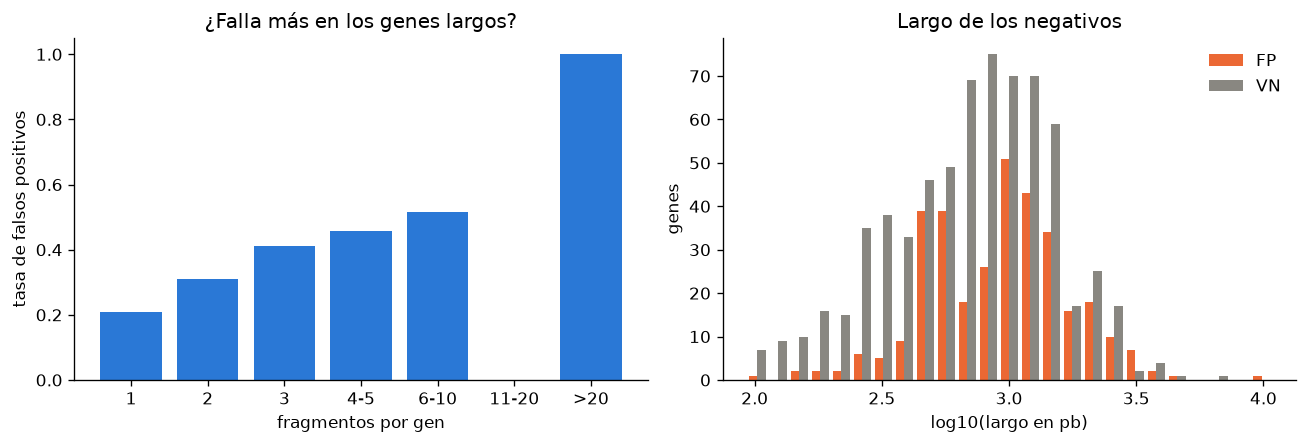

In [6]:
import matplotlib.pyplot as plt

neg = res[res.y == 0]
print("Solo negativos (los que pueden ser FP):")
print(f"  mediana del largo  -> FP: {neg[neg.pred_or==1].largo.median():,.0f} pb | "
      f"VN: {neg[neg.pred_or==0].largo.median():,.0f} pb")
print(f"  mediana de n_frag  -> FP: {neg[neg.pred_or==1].n_frag.median():.0f} | "
      f"VN: {neg[neg.pred_or==0].n_frag.median():.0f}")

bins = [0, 1, 2, 3, 5, 10, 20, 10**9]
etq  = ["1", "2", "3", "4-5", "6-10", "11-20", ">20"]
neg = neg.assign(grupo=pd.cut(neg.n_frag, bins=bins, labels=etq, right=True))
tab = neg.groupby("grupo", observed=True).agg(
    genes=("gen", "size"), falsos_pos=("pred_or", "sum"))
tab["tasa_FP"] = (tab.falsos_pos / tab.genes).round(3)
print("\nTasa de falsos positivos según cuántos fragmentos tiene el gen:")
print(tab.to_string())
print("\nSi la tasa sube con el nº de fragmentos, la regla OR es parte del problema:")
print("un gen largo tiene más oportunidades de que ALGÚN fragmento se pase del umbral.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), dpi=120)
ax[0].bar(tab.index.astype(str), tab.tasa_FP, color="#2a78d6")
ax[0].set_xlabel("fragmentos por gen"); ax[0].set_ylabel("tasa de falsos positivos")
ax[0].set_title("¿Falla más en los genes largos?")
for s in ("top", "right"): ax[0].spines[s].set_visible(False)

ax[1].hist([np.log10(neg[neg.pred_or==1].largo), np.log10(neg[neg.pred_or==0].largo)],
           bins=25, label=["FP", "VN"], color=["#eb6834", "#898781"])
ax[1].set_xlabel("log10(largo en pb)"); ax[1].set_ylabel("genes"); ax[1].legend(frameon=False)
ax[1].set_title("Largo de los negativos")
for s in ("top", "right"): ax[1].spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(SALIDA / "diagnostico_largo.png", dpi=200); plt.show()

## Celda 7 — Reglas alternativas (diagnóstico, no elección)

Compara la regla actual con otras más exigentes. Si una se ve mucho mejor, ya tienes una línea de mejora
concreta que mostrarle a tu asesora.

**Importante y hay que decirlo así:** estos números salen del 1k+1k, que es el conjunto de evaluación. Mirar
varias reglas aquí y quedarse con la mejor sería elegir sobre el test, y el resultado saldría inflado. La
regla se elige con el entrenamiento o la validación (el cuaderno del umbral ya tiene ese procedimiento) y el
1k+1k solo se usa para reportar el número final. Esta celda es para *ver* si vale la pena, no para decidir.

In [7]:
# DIAGNÓSTICO, NO ELECCIÓN: el 1k+1k solo mide. Si una regla se ve mejor,
# hay que elegirla con el entrenamiento/validación y recién después reportarla aquí.
def met(y, pred):
    VP = int(((y==1)&(pred==1)).sum()); FP = int(((y==0)&(pred==1)).sum()); FN = int(((y==1)&(pred==0)).sum())
    return dict(recall=round(VP/max(1,VP+FN),3), precision=round(VP/max(1,VP+FP),3),
                f1=round(2*VP/max(1,2*VP+FP+FN),3), FP=FP, FN=FN)

reglas = {
    "OR (actual): >=1 fragmento":  (res.n_frag_pos >= 1),
    ">= 2 fragmentos":             (res.n_frag_pos >= 2),
    ">= 25 % de los fragmentos":   (res.frac_pos >= 0.25),
    ">= 50 % de los fragmentos":   (res.frac_pos >= 0.50),
    "probabilidad media > 0.5":    (res.p_media > 0.5),
}
print(pd.DataFrame({k: met(res.y.values, v.astype(int).values) for k, v in reglas.items()}).T.to_string())

                            recall  precision     f1     FP     FN
OR (actual): >=1 fragmento   0.896      0.730  0.804  332.0  104.0
>= 2 fragmentos              0.544      0.880  0.672   74.0  456.0
>= 25 % de los fragmentos    0.894      0.743  0.812  309.0  106.0
>= 50 % de los fragmentos    0.845      0.806  0.825  204.0  155.0
probabilidad media > 0.5     0.783      0.847  0.814  141.0  217.0
